## LINEAR REGRESSION

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ds = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')
ds.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [3]:
ds.shape

(2111, 17)

In [4]:
np.unique('NObeyesdad')

array(['NObeyesdad'], dtype='<U10')

In [5]:
ds['NObeyesdad'].unique()

array(['Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II',
       'Obesity_Type_I', 'Insufficient_Weight', 'Obesity_Type_II',
       'Obesity_Type_III'], dtype=object)

In [6]:
category = {
    'Normal_Weight': 0,
    'Overweight_Level_I': 1,
    'Overweight_Level_II': 2,
    'Obesity_Type_I': 3,
    'Insufficient_Weight': 4,
    'Obesity_Type_II': 5,
    'Obesity_Type_III': 6
}

In [7]:
ds['NObeyesdad'] = ds['NObeyesdad'].map(category)

In [8]:
ds.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,0
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,0
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,0
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,1
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,2


In [9]:
missing_data =ds.isnull()
print(missing_data)

      Gender    Age  Height  Weight  family_history_with_overweight   FAVC  \
0      False  False   False   False                           False  False   
1      False  False   False   False                           False  False   
2      False  False   False   False                           False  False   
3      False  False   False   False                           False  False   
4      False  False   False   False                           False  False   
...      ...    ...     ...     ...                             ...    ...   
2106   False  False   False   False                           False  False   
2107   False  False   False   False                           False  False   
2108   False  False   False   False                           False  False   
2109   False  False   False   False                           False  False   
2110   False  False   False   False                           False  False   

       FCVC    NCP   CAEC  SMOKE   CH2O    SCC    FAF    TUE   

In [10]:
print (ds.dtypes)

Gender                             object
Age                               float64
Height                            float64
Weight                            float64
family_history_with_overweight     object
FAVC                               object
FCVC                              float64
NCP                               float64
CAEC                               object
SMOKE                              object
CH2O                              float64
SCC                                object
FAF                               float64
TUE                               float64
CALC                               object
MTRANS                             object
NObeyesdad                          int64
dtype: object


In [11]:
for col in ds.select_dtypes(include=['object']).columns:
    ds[col] = ds[col].astype('category').cat.codes  

ds = ds.astype(int)

print(ds.dtypes)

Gender                            int64
Age                               int64
Height                            int64
Weight                            int64
family_history_with_overweight    int64
FAVC                              int64
FCVC                              int64
NCP                               int64
CAEC                              int64
SMOKE                             int64
CH2O                              int64
SCC                               int64
FAF                               int64
TUE                               int64
CALC                              int64
MTRANS                            int64
NObeyesdad                        int64
dtype: object


In [12]:
new = ds.loc[:,["Age","NObeyesdad"]]
new

,Age,NObeyesdad
0,21,0
1,21,0
2,23,0
3,27,1
4,22,2
...,...,...
2106,20,6
2107,21,6
2108,22,6
2109,24,6


In [13]:
X = ds['Age'].values
Y = ds['NObeyesdad'].values

In [14]:
X_mean = X.mean()

In [15]:
print (X_mean)

23.972524869729988


In [16]:
Y_mean = Y.mean()

In [17]:
print (Y_mean)

3.0506868782567502


In [18]:
dev_X =(ds['Age']-X_mean)

In [19]:
dev_X

0      -2.972525
1      -2.972525
2      -0.972525
3       3.027475
4      -1.972525
          ...   
2106   -3.972525
2107   -2.972525
2108   -1.972525
2109    0.027475
2110   -0.972525
Name: Age, Length: 2111, dtype: float64

In [20]:
dev_Y =(ds['NObeyesdad']-Y_mean)

In [21]:
dev_Y

0      -3.050687
1      -3.050687
2      -3.050687
3      -2.050687
4      -1.050687
          ...   
2106    2.949313
2107    2.949313
2108    2.949313
2109    2.949313
2110    2.949313
Name: NObeyesdad, Length: 2111, dtype: float64

In [22]:
product_of_dev = dev_Y * dev_X
product_of_dev

0        9.068243
1        9.068243
2        2.966869
3       -6.208404
4        2.072506
          ...    
2106   -11.716220
2107    -8.766907
2108    -5.817593
2109     0.081033
2110    -2.868280
Length: 2111, dtype: float64

In [23]:
devSq = dev_X**2
devSq 

0        8.835904
1        8.835904
2        0.945805
3        9.165606
4        3.890854
          ...    
2106    15.780954
2107     8.835904
2108     3.890854
2109     0.000755
2110     0.945805
Name: Age, Length: 2111, dtype: float64

In [24]:
slope = product_of_dev.sum()/devSq.sum()
slope

np.float64(0.021255253880889176)

In [25]:
intercept = Y_mean - (slope*X_mean)
intercept

np.float64(2.5411447759847094)

In [26]:
xtrain =ds['Age']
ytrain = ds['NObeyesdad']

In [27]:
y = slope*xtrain + intercept

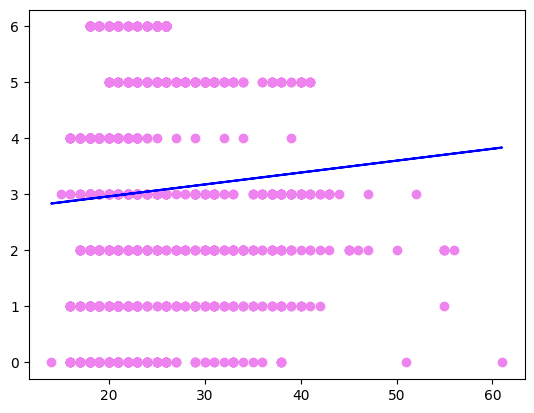

In [28]:
plt.scatter(xtrain, ytrain, c='violet')
plt.plot(xtrain, y, color ='blue')
plt.show()

In [29]:
error = ytrain-y
error

0      -2.987505
1      -2.987505
2      -3.030016
3      -2.115037
4      -1.008760
          ...   
2106    3.033750
2107    3.012495
2108    2.991240
2109    2.948729
2110    2.969984
Length: 2111, dtype: float64

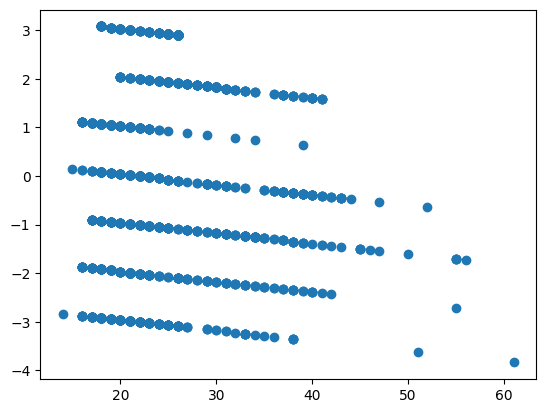

In [30]:
plt.scatter(xtrain, error)

In [31]:
errorSq= error**2
errorSq

0       8.925187
1       8.925187
2       9.180995
3       4.473380
4       1.017597
          ...   
2106    9.203640
2107    9.075125
2108    8.947515
2109    8.695003
2110    8.820807
Length: 2111, dtype: float64

In [32]:
mse =(errorSq.sum())/ds.shape[0]
mse

np.float64(3.962878803689137)

In [33]:
E1 =errorSq.sum()
E2 =((ytrain-Y_mean)**2).sum()
E2

np.float64(8403.576504026529)

In [34]:
R2=1-E1/E2
R2

np.float64(0.004514666989772986)

In [35]:
print(f"Slope: {slope}")
print(f"Intercept: {intercept}")
print(f"Mean Squared Error: {mse}")
print(f"R-squared: {R2}")

Slope: 0.021255253880889176
Intercept: 2.5411447759847094
Mean Squared Error: 3.962878803689137
R-squared: 0.004514666989772986
